In [1]:
#import torch
import pandas as pd
import os
import numpy as np
from tensorflow import keras
from tqdm import tqdm
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Softmax, Dropout
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from tensorflow.keras.wrappers.scikit_learn import KerasClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import train_test_split
from classification_models_1D.tfkeras import Classifiers

#device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#print(device)

In [2]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '0'
os.environ['TF_FORCE_GPU_ALLOW_GROWTH'] = 'true'
os.environ['CUDA_VISIBLE_DEVICES']='0'
os.environ['WANDB_WATCH'] = 'false'
tensorflow_version = float(tf.__version__[0:3])
import wandb
# Get the GPU memory fraction to allocate
gpu_memory_fraction = 0.8
gpu_options = tf.compat.v1.GPUOptions(per_process_gpu_memory_fraction=gpu_memory_fraction)
session = tf.compat.v1.Session(config=tf.compat.v1.ConfigProto(gpu_options=gpu_options))
#wandb.login()

2024-06-12 14:05:19.173272: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-06-12 14:05:20.293605: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:39] Overriding allow_growth setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
2024-06-12 14:05:20.293979: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 38941 MB memory:  -> device: 0, name: NVIDIA RTX A6000, pci bus id: 0000:01:00.0, compute capability: 8.6


In [3]:
#data = pd.read_parquet("/media/data1/ravram/DeepECG/ekg_waveforms_output/df_xml_2023_05_09_2004-to-june-2022_n_1572280_with_labelbox_no_duplicates.parquet")
data = pd.read_parquet("/media/data1/muse_ge/ECG_ad202207_1453937_cat_labels_original_diagnosis_v1.1.parquet")
data.dtypes

index                                         int64
npy_path                                     object
RestingECG_MuseInfo_MuseVersion              object
RestingECG_PatientDemographics_PatientID     object
RestingECG_PatientDemographics_PatientAge    object
                                              ...  
rythme auriculaire gauche                     int64
mauvaise qualité de l'ecg                     int64
bloc de branche droit                         int64
hémibloc antérieur gauche                     int64
dictionary_diagnosis                         object
Length: 583, dtype: object

In [4]:
import wandb
wandb.login()

Failed to detect the name of this notebook, you can set it manually with the WANDB_NOTEBOOK_NAME environment variable to enable code saving.


wandb: Currently logged in as: bahani-mourad (mhi_ai). Use `wandb login --relogin` to force relogin


True

In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split
from tqdm import tqdm
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from sklearn.utils import indexable, _safe_indexing
from sklearn.utils.validation import _num_samples
from sklearn.model_selection._split import _validate_shuffle_split
from itertools import chain


csv_path = "NICM__Data.csv"
NICM_DATA = pd.read_csv(csv_path)
pd.set_option('display.max_columns', None)
# Load the XLSX file)
print(NICM_DATA.shape)
NICM_DATA.head()

(372, 51)


,Unnamed: 0,Correspondance dossier 2,CMD,CMPNI,DOB,Cas index,HTA,DM,IRC,NYHA,AF_msc,age_afmsc,FA,TVNS,date_ECG_NICM,QRS_dur,QRS_bb,Bbloq,ARNI,ACEouARA,ARM,ISGLT-2,Diuretique,Sex,Mutation,Gene,Amino Acid,DNA Change,DateFirstFU,Date_FirstMRI,CMR01,CMR_LVEF,CMR_LGE,LV_LGE,RVEF,HolterDx,MaxHolterPVCcountDx,DateHolterDx,ICD,Date_ICDimplantation,LTVAafterDx,DateLTVAafterDx,LTVAafterDx_CL,SevereLTVAafterDx,DateSevereLTVAafterDx,SevereLTVAafterDx_CL,DateLFU,DurationFU,AgeatDx,LTVA01,MRN
0,0,NICM1,CMD,yes,1990-07-01 00:00:00,1,0,0,0,2,0,NaN,0,0.0,2018-05-07 00:00:00,92,0,1.0,1.0,0.0,0.0,0.0,0.0,1,0.0,TPM1,p.Lys259Glu,c.775A>G,2018-09-12,2018-07-01 00:00:00,1,44.0,1,0.0,38.0,1.0,1,2018-11-13 00:00:00,0,NaN,0,NaN,NaN,0.0,NaN,NaN,2023-07-21,5.208219,28.219178,0,544960
1,1,NICM2,CMD,yes,1970-10-14 00:00:00,1,1,0,0,1,0,NaN,0,0.0,2018-07-05 00:00:00,106,0,1.0,1.0,0.0,0.0,0.0,0.0,1,1.0,MYBPC3 + TTN,p.Glu334Lys,c.1000G>A,2015-07-05,2017-01-12 00:00:00,1,43.0,1,1.0,59.0,0.0,NaN,NaN,0,NaN,0,NaN,NaN,0.0,NaN,NaN,2023-08-16,5.117808,44.753425,0,536354
2,2,NICM3,CMD,yes,1975-10-03 00:00:00,1,0,0,0,1,0,NaN,0,1.0,2012-12-07 00:00:00,82,0,1.0,1.0,0.0,0.0,0.0,0.0,1,0.0,NaN,NaN,NaN,2012-11-01,2012-12-10 00:00:00,1,29.0,1,0.0,36.0,0.0,NaN,NaN,1,2021-01-12 00:00:00,0,NaN,NaN,0.0,NaN,NaN,2024-03-19,11.287671,37.106849,0,463109
3,3,NICM4,CMD,yes,1955-10-21 00:00:00,1,1,0,0,1,0,NaN,3,1.0,2021-06-01 00:00:00,90,0,1.0,0.0,1.0,0.0,0.0,0.0,1,0.0,LMNA,p.(Arg72His),c.215G>A,2021-06-18,2021-06-25 00:00:00,1,34.0,1,1.0,41.0,1.0,2254,2023-01-06 00:00:00,1,2021-07-09 00:00:00,0,NaN,NaN,0.0,NaN,NaN,2023-01-19,1.635616,65.704110,0,591660
4,4,NICM5,CMD,yes,1948-02-03 00:00:00,1,0,1,0,2,0,NaN,0,1.0,2020-08-19 00:00:00,82,0,1.0,0.0,1.0,0.0,0.0,1.0,1,0.0,NaN,NaN,NaN,2020-06-01,2020-06-01 00:00:00,1,21.0,1,1.0,28.0,1.0,87,2021-07-16 00:00:00,0,NaN,0,NaN,NaN,0.0,NaN,NaN,2024-01-10,3.394521,72.375342,0,575300


In [6]:
fam_ecg = NICM_DATA["MRN"].values.tolist()
fam_ecg = list(map(str,fam_ecg))
#data['RestingECG_PatientDemographics_PatientID'] = [str(i).replace("'","") for i in data['RestingECG_PatientDemographics_PatientID'].tolist()]
#data['RestingECG_PatientDemographics_PatientID'] = [str(i).zfill(7) for i in data['RestingECG_PatientDemographics_PatientID'].tolist()]
#data['RestingECG_PatientDemographics_PatientID'] = data['RestingECG_PatientDemographics_PatientID'].str.strip()

fam_ecg = [x.zfill(7) for x in fam_ecg]

# Now try creating the subset
data_ = data.loc[data['RestingECG_PatientDemographics_PatientID'].isin(fam_ecg)]
data_.shape


(4677, 583)

In [7]:
import pickle
#with open('NICM_Test_ids_list.pkl', 'wb') as f:pickle.dump(ids_test, f) #ids_test.append("0315104")ids_test.append("0320362")
with open('NICM_Test_ids_list.pkl', 'rb') as file:
    ids_test = pickle.load(file)

ids_test = [str(x).zfill(7) for x in ids_test[:-2]]

test_data_ = data_.loc[data_['RestingECG_PatientDemographics_PatientID'].isin(ids_test)]

train_data_ = data_.loc[~data_['RestingECG_PatientDemographics_PatientID'].isin(ids_test)]



In [17]:
train_label = []
test_label = []

Train_feature = []

Test_feature = []
sub_set_ID = train_data_["RestingECG_PatientDemographics_PatientID"].values.tolist()
for patient_ID in  sub_set_ID:
    Train_feature.append(NICM_DATA.loc[NICM_DATA['MRN'] == int(patient_ID), :].values.flatten())

sub_set_ID = test_data_["RestingECG_PatientDemographics_PatientID"].values.tolist()
for patient_ID in  sub_set_ID:
    Test_feature.append(NICM_DATA.loc[NICM_DATA['MRN'] == int(patient_ID), :].values.flatten())
Train_feature = pd.DataFrame(Train_feature, columns=NICM_DATA.columns)
Test_feature = pd.DataFrame(Test_feature, columns=NICM_DATA.columns)


train_CV = Train_feature
print(train_CV.shape)
train_CV.head()
train_label = train_CV["LTVA01"].values.tolist()
test_label = Test_feature["LTVA01"].values.tolist()



(3874, 51)


In [18]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()


train_CV = Train_feature
test_cv = Test_feature 

training_file_path = train_data_["npy_path"].values.tolist()
test_images_path = test_data_["npy_path"].values.tolist()


train_CV["npy_path"] = training_file_path 
test_cv["npy_path"] = test_images_path

train_CV["Age"] = train_data_["RestingECG_PatientDemographics_PatientAge"].values.tolist()
test_cv["Age"] = test_data_["RestingECG_PatientDemographics_PatientAge"].values.tolist()
train_CV['Age'] = scaler.fit_transform(train_CV[['Age']])
test_cv['Age'] = scaler.fit_transform(test_cv[['Age']])

train_CV.shape

(3874, 53)

In [19]:
test_cv["RestingECG_TestDemographics_AcquisitionDate"] = [str(j) for j in test_data_["RestingECG_TestDemographics_AcquisitionDate"]]
test_cv["RestingECG_TestDemographics_AcquisitionDate"] =  [str(i).replace("00:00:00","") for i in test_cv["RestingECG_TestDemographics_AcquisitionDate"].values.tolist()]
test_cv['RestingECG_TestDemographics_AcquisitionDate'] = pd.to_datetime(test_cv['RestingECG_TestDemographics_AcquisitionDate'])
test_cv["date_ECG_NICM"] = [str(j).replace("00:00:00","").replace("//","/").replace("/","-") for j in test_cv["date_ECG_NICM"]]
test_cv['date_ECG_NICM'] = pd.to_datetime(test_cv['date_ECG_NICM'])

train_CV["RestingECG_TestDemographics_AcquisitionDate"] = [str(j) for j in train_data_["RestingECG_TestDemographics_AcquisitionDate"]]
train_CV["RestingECG_TestDemographics_AcquisitionDate"] =  [str(i).replace("00:00:00","") for i in train_CV["RestingECG_TestDemographics_AcquisitionDate"].values.tolist()]
train_CV['RestingECG_TestDemographics_AcquisitionDate'] = pd.to_datetime(train_CV['RestingECG_TestDemographics_AcquisitionDate'])
train_CV["date_ECG_NICM"] = [str(j).replace("00:00:00","").replace("//","/").replace("/","-") for j in train_CV["date_ECG_NICM"]]
train_CV['date_ECG_NICM'] = pd.to_datetime(train_CV['date_ECG_NICM'])
train_CV.head()

,Unnamed: 0,Correspondance dossier 2,CMD,CMPNI,DOB,Cas index,HTA,DM,IRC,NYHA,AF_msc,age_afmsc,FA,TVNS,date_ECG_NICM,QRS_dur,QRS_bb,Bbloq,ARNI,ACEouARA,ARM,ISGLT-2,Diuretique,Sex,Mutation,Gene,Amino Acid,DNA Change,DateFirstFU,Date_FirstMRI,CMR01,CMR_LVEF,CMR_LGE,LV_LGE,RVEF,HolterDx,MaxHolterPVCcountDx,DateHolterDx,ICD,Date_ICDimplantation,LTVAafterDx,DateLTVAafterDx,LTVAafterDx_CL,SevereLTVAafterDx,DateSevereLTVAafterDx,SevereLTVAafterDx_CL,DateLFU,DurationFU,AgeatDx,LTVA01,MRN,npy_path,Age,RestingECG_TestDemographics_AcquisitionDate
0,139,NICM157,CMD,yes,1946-07-26 00:00:00,1,0,0,0,2,0,NaN,0,0.0,2015-09-26,144,1,1.0,0.0,0.0,0.0,0.0,0.0,0,0.0,NaN,NaN,NaN,1989-09-14,2019-09-30 00:00:00,1,36.0,1,0.0,56.0,0.0,NaN,NaN,0,NaN,0,NaN,NaN,0.0,NaN,NaN,2023-10-10,8.043836,43.167123,0,138467,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,0.870968,2017-12-21
1,139,NICM157,CMD,yes,1946-07-26 00:00:00,1,0,0,0,2,0,NaN,0,0.0,2015-09-26,144,1,1.0,0.0,0.0,0.0,0.0,0.0,0,0.0,NaN,NaN,NaN,1989-09-14,2019-09-30 00:00:00,1,36.0,1,0.0,56.0,0.0,NaN,NaN,0,NaN,0,NaN,NaN,0.0,NaN,NaN,2023-10-10,8.043836,43.167123,0,138467,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,0.870968,2017-12-20
2,139,NICM157,CMD,yes,1946-07-26 00:00:00,1,0,0,0,2,0,NaN,0,0.0,2015-09-26,144,1,1.0,0.0,0.0,0.0,0.0,0.0,0,0.0,NaN,NaN,NaN,1989-09-14,2019-09-30 00:00:00,1,36.0,1,0.0,56.0,0.0,NaN,NaN,0,NaN,0,NaN,NaN,0.0,NaN,NaN,2023-10-10,8.043836,43.167123,0,138467,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,0.870968,2017-12-20
3,139,NICM157,CMD,yes,1946-07-26 00:00:00,1,0,0,0,2,0,NaN,0,0.0,2015-09-26,144,1,1.0,0.0,0.0,0.0,0.0,0.0,0,0.0,NaN,NaN,NaN,1989-09-14,2019-09-30 00:00:00,1,36.0,1,0.0,56.0,0.0,NaN,NaN,0,NaN,0,NaN,NaN,0.0,NaN,NaN,2023-10-10,8.043836,43.167123,0,138467,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,0.661290,2004-12-14
4,139,NICM157,CMD,yes,1946-07-26 00:00:00,1,0,0,0,2,0,NaN,0,0.0,2015-09-26,144,1,1.0,0.0,0.0,0.0,0.0,0.0,0,0.0,NaN,NaN,NaN,1989-09-14,2019-09-30 00:00:00,1,36.0,1,0.0,56.0,0.0,NaN,NaN,0,NaN,0,NaN,NaN,0.0,NaN,NaN,2023-10-10,8.043836,43.167123,0,138467,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,0.935484,2021-12-01


In [21]:
import pandas as pd
from datetime import datetime
today_date = pd.to_datetime(datetime.now().date())

# Define a function to sort each group by the nearest date to today
def sort_by_nearest_date(group):
    return group.assign(
        distance_to_today=abs(group['RestingECG_TestDemographics_AcquisitionDate'] - today_date)
    ).sort_values(by='distance_to_today').drop(columns='distance_to_today')

# Sort each group by the nearest date to today using groupby and apply
sorted_df = test_cv.groupby('MRN', group_keys=False).apply(sort_by_nearest_date)

# Reset index after sorting
sorted_df.reset_index(drop=True, inplace=True)

import pandas as pd
import datetime

def convert_excel_date(excel_date):
    try:
        # Check if the value is a number (Excel date)
        temp = datetime.datetime(1899, 12, 30)  # Correct base date
        delta = datetime.timedelta(days=int(float(excel_date)))
        converted_date = temp + delta
        return converted_date.strftime("%Y-%m-%d")
    except (ValueError, TypeError):
        # If conversion fails, return the original value (assuming it's a string date)
        return excel_date

# Apply conversion function
sorted_df["DateLTVAafterDx"] = [convert_excel_date(j) if not pd.isnull(j) else j for j in sorted_df["DateLTVAafterDx"]]

# Convert all dates to datetime format
sorted_df["DateLTVAafterDx"] = pd.to_datetime(sorted_df["DateLTVAafterDx"], errors='coerce')

# Ensure all dates are in a consistent format
sorted_df["DateLTVAafterDx"] = sorted_df["DateLTVAafterDx"].dt.strftime("%Y-%m-%d")

# Convert back to datetime for date comparison
sorted_df["DateLTVAafterDx"] = pd.to_datetime(sorted_df["DateLTVAafterDx"], errors='coerce')


import datetime
import pandas as pd

# Get today's date
today_date = pd.to_datetime(datetime.datetime.now().date())

# Define a function to calculate the absolute difference between each date and today's date
def nearest_to_today(row):
    date1 = row['RestingECG_TestDemographics_AcquisitionDate']
    date2 = row['DateLTVAafterDx']
    
    if pd.isnull(date1) and pd.isnull(date2):
        return False  # Both dates are missing, no meaningful comparison can be made
    elif pd.isnull(date1):
        return False  # 'RestingECG_TestDemographics_AcquisitionDate' is missing
    elif pd.isnull(date2):
        return True  # 'DateLTVAafterDx' is missing, consider it as nearest to today
    else:
        today_date = pd.Timestamp.now().normalize()
        return abs(date1 - today_date) > abs(date2 - today_date)

# Filter the DataFrame based on the nearest date to today
filtered_df = sorted_df[sorted_df.apply(nearest_to_today, axis=1)]

import datetime
import pandas as pd

# Get today's date
today_date = pd.to_datetime(datetime.datetime.now().date())

# Define a function to calculate the absolute difference between each date and today's date
def nearest_to_today__(row):
    date1 = row['RestingECG_TestDemographics_AcquisitionDate']
    date2 = row['date_ECG_NICM']
    
    if pd.isnull(date1) and pd.isnull(date2):
        return False  # Both dates are missing, no meaningful comparison can be made
    elif pd.isnull(date1):
        return False  # 'RestingECG_TestDemographics_AcquisitionDate' is missing
    elif pd.isnull(date2):
        return True  # 'DateLTVAafterDx' is missing, consider it as nearest to today
    else:
        today_date = pd.Timestamp.now().normalize()
        return abs(date1 - today_date) < abs(date2 - today_date)

# Filter the DataFrame based on the nearest date to today
filtered_df = filtered_df[filtered_df.apply(nearest_to_today__, axis=1)]


test_cv = filtered_df
test_cv.shape

(478, 54)

In [22]:
import pandas as pd
from datetime import datetime
today_date = pd.to_datetime(datetime.now().date())

# Define a function to sort each group by the nearest date to today
def sort_by_nearest_date(group):
    return group.assign(
        distance_to_today=abs(group['RestingECG_TestDemographics_AcquisitionDate'] - today_date)
    ).sort_values(by='distance_to_today').drop(columns='distance_to_today')

# Sort each group by the nearest date to today using groupby and apply
sorted_df = train_CV.groupby('MRN', group_keys=False).apply(sort_by_nearest_date)

# Reset index after sorting
sorted_df.reset_index(drop=True, inplace=True)

import pandas as pd
import datetime

def convert_excel_date(excel_date):
    try:
        # Check if the value is a number (Excel date)
        temp = datetime.datetime(1899, 12, 30)  # Correct base date
        delta = datetime.timedelta(days=int(float(excel_date)))
        converted_date = temp + delta
        return converted_date.strftime("%Y-%m-%d")
    except (ValueError, TypeError):
        # If conversion fails, return the original value (assuming it's a string date)
        return excel_date

# Apply conversion function
sorted_df["DateLTVAafterDx"] = [convert_excel_date(j) if not pd.isnull(j) else j for j in sorted_df["DateLTVAafterDx"]]

# Convert all dates to datetime format
sorted_df["DateLTVAafterDx"] = pd.to_datetime(sorted_df["DateLTVAafterDx"], errors='coerce')

# Ensure all dates are in a consistent format
sorted_df["DateLTVAafterDx"] = sorted_df["DateLTVAafterDx"].dt.strftime("%Y-%m-%d")

# Convert back to datetime for date comparison
sorted_df["DateLTVAafterDx"] = pd.to_datetime(sorted_df["DateLTVAafterDx"], errors='coerce')


import datetime
import pandas as pd

# Get today's date
today_date = pd.to_datetime(datetime.datetime.now().date())

# Define a function to calculate the absolute difference between each date and today's date
def nearest_to_today(row):
    date1 = row['RestingECG_TestDemographics_AcquisitionDate']
    date2 = row['DateLTVAafterDx']
    
    if pd.isnull(date1) and pd.isnull(date2):
        return False  # Both dates are missing, no meaningful comparison can be made
    elif pd.isnull(date1):
        return False  # 'RestingECG_TestDemographics_AcquisitionDate' is missing
    elif pd.isnull(date2):
        return True  # 'DateLTVAafterDx' is missing, consider it as nearest to today
    else:
        today_date = pd.Timestamp.now().normalize()
        return abs(date1 - today_date) > abs(date2 - today_date)

# Filter the DataFrame based on the nearest date to today
filtered_df = sorted_df[sorted_df.apply(nearest_to_today, axis=1)]

import datetime
import pandas as pd

# Get today's date
today_date = pd.to_datetime(datetime.datetime.now().date())

# Define a function to calculate the absolute difference between each date and today's date
def nearest_to_today__(row):
    date1 = row['RestingECG_TestDemographics_AcquisitionDate']
    date2 = row['date_ECG_NICM']
    
    if pd.isnull(date1) and pd.isnull(date2):
        return False  # Both dates are missing, no meaningful comparison can be made
    elif pd.isnull(date1):
        return False  # 'RestingECG_TestDemographics_AcquisitionDate' is missing
    elif pd.isnull(date2):
        return True  # 'DateLTVAafterDx' is missing, consider it as nearest to today
    else:
        today_date = pd.Timestamp.now().normalize()
        return abs(date1 - today_date) < abs(date2 - today_date)

# Filter the DataFrame based on the nearest date to today
filtered_df = filtered_df[filtered_df.apply(nearest_to_today__, axis=1)]


train_CV = filtered_df
train_CV.shape

(2637, 54)

In [ ]:
train_label = train_CV["LTVA01"].values.tolist()
test_label = test_cv["LTVA01"].values.tolist()
d = {"train":train_label, "test":test_label}
for i in d:
    plt.hist(d[i], bins=[0, 1, 2.0], edgecolor='black')  # Specifying bin edges for discrete classes
    plt.xlabel('Class')
    plt.ylabel('Frequency')
    plt.title(f'Histogram of Classes in {i} set')
    plt.xticks([0, 1])  # Setting ticks for discrete classes
    plt.show()
    print("the number of ones :"+str(d[i].count(1))+ " with percentage : "+str((d[i].count(1)/len(d[i]))*100)+"%")
    print("the number of zeros :"+str(d[i].count(0))+ " with percentage : "+str((d[i].count(0)/len(d[i]))*100)+"%")
    print("the total is :",len(d[i]))

In [34]:
#1174  2493-1174-1174-145                                1.0 == 1174    0.0 2493


filtered_df = train_CV[train_CV['LTVA01'] == 1.0]
filtered_df_0 = train_CV[train_CV['LTVA01'] == 0.0]

# Count the occurrences of each ID in the filtered DataFrame
id_counts_with_label = filtered_df['MRN'].value_counts()

# Determine the IDs that need to be replicated
ids_to_replicate = id_counts_with_label[id_counts_with_label < 106].index

# Replicate rows for each ID that does not have at least 28 occurrences
replicated_rows = filtered_df[filtered_df['MRN'].isin(ids_to_replicate)].groupby('MRN').apply(lambda x: x.sample(106 - len(x), replace=True))

# Concatenate the original DataFrame with the replicated rows
balanced_dataset = pd.concat([filtered_df_0,filtered_df, replicated_rows])

# Display the result
print(balanced_dataset.shape)
balanced_dataset.head()

(4476, 54)


,Unnamed: 0,Correspondance dossier 2,CMD,CMPNI,DOB,Cas index,HTA,DM,IRC,NYHA,AF_msc,age_afmsc,FA,TVNS,date_ECG_NICM,QRS_dur,QRS_bb,Bbloq,ARNI,ACEouARA,ARM,ISGLT-2,Diuretique,Sex,Mutation,Gene,Amino Acid,DNA Change,DateFirstFU,Date_FirstMRI,CMR01,CMR_LVEF,CMR_LGE,LV_LGE,RVEF,HolterDx,MaxHolterPVCcountDx,DateHolterDx,ICD,Date_ICDimplantation,LTVAafterDx,DateLTVAafterDx,LTVAafterDx_CL,SevereLTVAafterDx,DateSevereLTVAafterDx,SevereLTVAafterDx_CL,DateLFU,DurationFU,AgeatDx,LTVA01,MRN,npy_path,Age,RestingECG_TestDemographics_AcquisitionDate
0,139,NICM157,CMD,yes,1946-07-26 00:00:00,1,0,0,0,2,0,NaN,0,0.0,2015-09-26,144,1,1.0,0.0,0.0,0.0,0.0,0.0,0,0.0,NaN,NaN,NaN,1989-09-14,2019-09-30 00:00:00,1,36.0,1,0.0,56.0,0.0,NaN,NaN,0,NaN,0,NaT,NaN,0.0,NaN,NaN,2023-10-10,8.043836,43.167123,0,138467,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,0.935484,2021-12-01
1,139,NICM157,CMD,yes,1946-07-26 00:00:00,1,0,0,0,2,0,NaN,0,0.0,2015-09-26,144,1,1.0,0.0,0.0,0.0,0.0,0.0,0,0.0,NaN,NaN,NaN,1989-09-14,2019-09-30 00:00:00,1,36.0,1,0.0,56.0,0.0,NaN,NaN,0,NaN,0,NaT,NaN,0.0,NaN,NaN,2023-10-10,8.043836,43.167123,0,138467,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,0.935484,2021-11-02
2,139,NICM157,CMD,yes,1946-07-26 00:00:00,1,0,0,0,2,0,NaN,0,0.0,2015-09-26,144,1,1.0,0.0,0.0,0.0,0.0,0.0,0,0.0,NaN,NaN,NaN,1989-09-14,2019-09-30 00:00:00,1,36.0,1,0.0,56.0,0.0,NaN,NaN,0,NaN,0,NaT,NaN,0.0,NaN,NaN,2023-10-10,8.043836,43.167123,0,138467,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,0.919355,2021-07-21
3,139,NICM157,CMD,yes,1946-07-26 00:00:00,1,0,0,0,2,0,NaN,0,0.0,2015-09-26,144,1,1.0,0.0,0.0,0.0,0.0,0.0,0,0.0,NaN,NaN,NaN,1989-09-14,2019-09-30 00:00:00,1,36.0,1,0.0,56.0,0.0,NaN,NaN,0,NaN,0,NaT,NaN,0.0,NaN,NaN,2023-10-10,8.043836,43.167123,0,138467,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,0.919355,2021-07-01
4,139,NICM157,CMD,yes,1946-07-26 00:00:00,1,0,0,0,2,0,NaN,0,0.0,2015-09-26,144,1,1.0,0.0,0.0,0.0,0.0,0.0,0,0.0,NaN,NaN,NaN,1989-09-14,2019-09-30 00:00:00,1,36.0,1,0.0,56.0,0.0,NaN,NaN,0,NaN,0,NaT,NaN,0.0,NaN,NaN,2023-10-10,8.043836,43.167123,0,138467,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,0.919355,2020-10-22


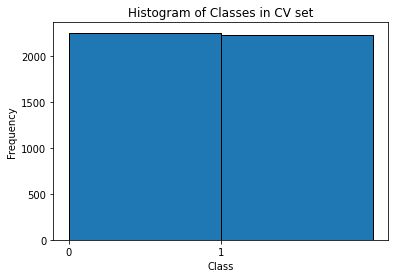

the number of ones :2226 with percentage : 49.73190348525469%
the number of zeros :2250 with percentage : 50.26809651474531%
the total is : 4476


In [35]:
l = balanced_dataset["LTVA01"].values.tolist()
plt.hist(l, bins=[0, 1, 2.0], edgecolor='black')  # Specifying bin edges for discrete classes
plt.xlabel('Class')
plt.ylabel('Frequency')
plt.title(f'Histogram of Classes in CV set')
plt.xticks([0, 1])  # Setting ticks for discrete classes
plt.show()
print("the number of ones :"+str(l.count(1.0))+ " with percentage : "+str((l.count(1.0)/len(l))*100)+"%")
print("the number of zeros :"+str(l.count(0.0))+ " with percentage : "+str((l.count(0.0)/len(l))*100)+"%")
print("the total is :",len(l))

In [36]:
s = balanced_dataset["MRN"].values.tolist()
for i in test_cv["MRN"].values.tolist():
    if i in s:
        print(i)

In [37]:
training_file_path = train_data_["npy_path"].values.tolist()

test_images_path = test_data_["npy_path"].values.tolist()
print(len(test_images_path))
print(len(test_label))
print(len(training_file_path))

803
478
3874


In [38]:
# Generator with Shuffle 
import numpy as np
from tensorflow.keras.utils import Sequence

class DataGenerator(Sequence):
    def __init__(self, x_set, y_set, batch_size, shuffle=True):
        self.x, self.y = x_set, y_set
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indexes = np.arange(len(self.x))
        if self.shuffle:
            np.random.shuffle(self.indexes)

    def __len__(self):
        return int(np.ceil(len(self.x) / float(self.batch_size)))

    def __getitem__(self, idx):
        start_idx = idx * self.batch_size
        end_idx = (idx + 1) * self.batch_size

        batch_indices = self.indexes[start_idx:end_idx]
        batch_x = self.x[batch_indices].astype(np.float32)
        batch_y = self.y[batch_indices].astype(np.float32)

        return batch_x, batch_y

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indexes)

In [39]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
def load_and_preprocess_ecg(path):
    with open(path, 'rb') as f:
          ecg = np.load(f)
          a,b,c = ecg.shape
          scaler.fit(ecg.reshape(a*b*c).reshape(-1,1))
          ecg = scaler.transform(ecg.reshape(a*b*c).reshape(-1,1))
          ecg = np.squeeze(ecg.reshape((c,a,b)))

    return ecg


trainCV_ECG_path = train_CV["npy_path"].values.tolist()
trainCV_data = np.empty([len(trainCV_ECG_path),2500,12])
for i, path in enumerate(trainCV_ECG_path):
     trainCV_data[i,:,:] = load_and_preprocess_ecg(path)


Balanced_ECG_path = balanced_dataset["npy_path"].values.tolist()
BalancedCV_data = np.empty([len(Balanced_ECG_path),2500,12])
for i, path in enumerate(Balanced_ECG_path):
     BalancedCV_data[i,:,:] = load_and_preprocess_ecg(path)



test_ECG_path = test_cv["npy_path"].values.tolist()
test___data = np.empty([len(test_ECG_path),2500,12])
for i, path in enumerate(test_ECG_path):
     test___data[i,:,:] = load_and_preprocess_ecg(path)


In [40]:
import pywt
from pywt import wavedec
from scipy.signal import medfilt
BASIC_SRATE = 500 #Hz
def denoise_signal(X, dwt_transform, dlevels, cutoff_low, cutoff_high):
    coeffs = wavedec(X, dwt_transform, level=dlevels)   # wavelet transform 'bior4.4'
    # scale 0 to cutoff_low 
    for ca in range(0,cutoff_low):
        coeffs[ca]=np.multiply(coeffs[ca],[0.0])
    # scale cutoff_high to end
    for ca in range(cutoff_high, len(coeffs)):
        coeffs[ca]=np.multiply(coeffs[ca],[0.0])
    Y = pywt.waverec(coeffs, dwt_transform) # inverse wavelet transform
    return Y  

def get_median_filter_width(sampling_rate, duration):
    res = int( sampling_rate*duration )
    res += ((res%2) - 1) # needs to be an odd number
    return res
# baseline fitting by filtering
# === Define Filtering Params for Baseline fitting Leads======================
ms_flt_array = [0.2,0.6]    #<-- length of baseline fitting filters (in seconds)
mfa = np.zeros(len(ms_flt_array), dtype='int')
for i in range(0, len(ms_flt_array)):
    mfa[i] = get_median_filter_width(BASIC_SRATE,ms_flt_array[i])

def filter_signal(X):
    global mfa
    X0 = X  #read orignal signal
    for mi in range(0,len(mfa)):
        X0 = medfilt(X0,mfa[mi]) # apply median filter one by one on top of each other
    X0 = np.subtract(X,X0)  # finally subtract from orignal signal
    return X0

def load_and_preprocess_ecg(path):
    with open(path, 'rb') as f:
          ecg = np.load(f)
          a,b,c = ecg.shape
          scaler.fit(ecg.reshape(a*b*c).reshape(-1,1))
          ecg = scaler.transform(ecg.reshape(a*b*c).reshape(-1,1))
          ecg = np.squeeze(ecg.reshape((c,a,b)))
          new_ecg = np.empty([2500,12])
          for i in range(12):
             new_ecg[:,i] = denoise_signal(ecg[:,i],'bior4.4', 9 , 1 , 7)
               

    return new_ecg

trainCV_ECG_path = train_CV["npy_path"].values.tolist()
trainCV_data_AUG = np.empty([len(trainCV_ECG_path),2500,12])
for i, path in enumerate(trainCV_ECG_path):
     trainCV_data_AUG[i,:,:] = load_and_preprocess_ecg(path)



/usr/local/lib/python3.8/dist-packages/pywt/_multilevel.py:43: UserWarning: Level value of 9 is too high: all coefficients will experience boundary effects.
  warnings.warn(
/usr/local/lib/python3.8/dist-packages/pywt/_multilevel.py:43: UserWarning: Level value of 9 is too high: all coefficients will experience boundary effects.
  warnings.warn(
/usr/local/lib/python3.8/dist-packages/pywt/_multilevel.py:43: UserWarning: Level value of 9 is too high: all coefficients will experience boundary effects.
  warnings.warn(
/usr/local/lib/python3.8/dist-packages/pywt/_multilevel.py:43: UserWarning: Level value of 9 is too high: all coefficients will experience boundary effects.
  warnings.warn(
/usr/local/lib/python3.8/dist-packages/pywt/_multilevel.py:43: UserWarning: Level value of 9 is too high: all coefficients will experience boundary effects.
  warnings.warn(
/usr/local/lib/python3.8/dist-packages/pywt/_multilevel.py:43: UserWarning: Level value of 9 is too high: all coefficients will ex

In [75]:
def load_and_preprocess_ecg(path):
    with open(path, 'rb') as f:
          ecg = np.load(f)
          a,b,c = ecg.shape
          scaler.fit(ecg.reshape(a*b*c).reshape(-1,1))
          ecg = scaler.transform(ecg.reshape(a*b*c).reshape(-1,1))
          ecg = np.squeeze(ecg.reshape((c,a,b)))
          new_ecg = np.empty([2500,12])
          for i in range(12):
             new_ecg[:,i] = filter_signal(ecg[:,i])
               
    return new_ecg


trainCV_ECG_path = train_CV["npy_path"].values.tolist()
trainCV_data_AUG2 = np.empty([len(trainCV_ECG_path),2500,12])
for i, path in enumerate(trainCV_ECG_path):
     trainCV_data_AUG2[i,:,:] = load_and_preprocess_ecg(path)


(4294, 2500, 12)

In [41]:
y_train = train_CV["LTVA01"]

y_test = test_cv["LTVA01"]
y_train, y_test =  np.array(y_train, dtype= np.float32), np.array(y_test, dtype= np.float32)


balaced_y_train = balanced_dataset["LTVA01"]

balaced_y_train= np.array(balaced_y_train, dtype= np.float32)



In [43]:
len(y_train[np.where(y_train == 0)[0]]) #-2*1159-817

2250

In [42]:
from sklearn.utils import class_weight
import gc

class_weights = class_weight.compute_class_weight('balanced',
                                                 np.unique(y_train),
                                                 y_train)
class_weights = dict(enumerate(class_weights))
print(class_weights)

class CleanMemory(tf.keras.callbacks.Callback):
  def on_epoch_end(self, epoch, logs=None):
    gc.collect()

{0: 0.586, 1: 3.4069767441860463}


/usr/local/lib/python3.8/dist-packages/sklearn/utils/validation.py:70: FutureWarning: Pass classes=[0. 1.], y=[0. 0. 0. ... 0. 0. 0.] as keyword args. From version 1.0 (renaming of 0.25) passing these as positional arguments will result in an error
  warnings.warn(f"Pass {args_msg} as keyword args. From version "


In [44]:
from keras import Model
from tensorflow.keras.layers import  Dense, Flatten
from keras.losses import BinaryCrossentropy
def make_model(model_name="resnet50"):
    
    loaded_architecture, _ = Classifiers.get(model_name)

    base = loaded_architecture(
        input_shape=(2500, 12),
        include_top=False,
        weights=None,
        pooling='avg'
        ) 

    x = Flatten()(base.output)
    x = Dropout(0.5)(x)
    x = Dense(1, activation='sigmoid', dtype='float32')(x) #
    model = Model(inputs=base.inputs, outputs=x) #regularizers.l2(0.0001)

    return model

model = make_model()

2024-06-12 14:22:10.903872: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 38941 MB memory:  -> device: 0, name: NVIDIA RTX A6000, pci bus id: 0000:01:00.0, compute capability: 8.6


In [45]:
loss=tf.keras.losses.BinaryFocalCrossentropy( gamma=2, from_logits=True)
def custom_loss_with_regularization(y_true, y_pred,loss_function = loss):
    # Binary crossentropy loss
    binary_crossentropy_loss = loss_function(y_true, y_pred)
        # L1 and L2 regularization terms
    l1_regularization = 0.0001  # Adjust the regularization strength as needed
    l2_regularization = 0.0001  # Adjust the regularization strength as needed

    # Get all trainable weights in the model
    trainable_weights = model.trainable_weights

    # Calculate L1 regularization term
    l1_loss = tf.add_n([tf.reduce_sum(tf.abs(w)) for w in trainable_weights])

    # Calculate L2 regularization term
    l2_loss = tf.add_n([tf.reduce_sum(tf.square(w)) for w in trainable_weights])

    # Add regularization terms to the loss
    total_loss = binary_crossentropy_loss + l1_regularization * l1_loss + l2_regularization * l2_loss

    return total_loss

In [46]:
model_path = 'pretrain_models/model_Resnet_50_AUC0.7265832812174275.h5'

# Load the model and provide the custom loss function in the custom_objects parameter
model = tf.keras.models.load_model(model_path, custom_objects={'custom_loss_with_regularization': custom_loss_with_regularization})

In [ ]:
run = wandb.init(
    # Set the project where this run will be logged
    project="ecg_project",
    # Track hyperparameters and run metadata
    config={
        "learning_rate": 0.001,
        "epochs": 200,
    },
)

In [ ]:
from tensorflow.keras.metrics import SensitivityAtSpecificity, SpecificityAtSensitivity
from keras.losses import BinaryCrossentropy
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve, auc, classification_report,ConfusionMatrixDisplay
import matplotlib.pyplot as plt


optimizer_ = tf.keras.optimizers.Adam(learning_rate=0.001)
optimizer_ = tf.keras.mixed_precision.LossScaleOptimizer(optimizer_)


Train_AUC = tf.keras.metrics.AUC(num_thresholds=10)



# Create and compile the model

model.compile(optimizer=optimizer_, 
              loss=custom_loss_with_regularization
              , metrics=['accuracy',Train_AUC])



label_class1, ecg_class1= y_train[np.where(y_train == 1)[0]],trainCV_data[np.where(y_train == 1)[0]]
label_class0, ecg_class0= y_train[np.where(y_train == 0)[0]][:1159],trainCV_data[np.where(y_train == 0)[0]][:1159]
Downsampled_data = np.concatenate((ecg_class1, ecg_class0), axis=0)
Downsampled_labels = np.concatenate((label_class1, label_class0), axis=0)

label_class1, ecg_class1= y_train[np.where(y_train == 1)[0]],trainCV_data[np.where(y_train == 1)[0]]
label_class0, ecg_class0= y_train[np.where(y_train == 0)[0]],trainCV_data[np.where(y_train == 0)[0]]
data_replicated  = np.concatenate((ecg_class1,ecg_class1, ecg_class1[:817]), axis=0)
label_replicated  = np.concatenate((label_class1,label_class1,label_class1[:817]), axis=0)
Oversampled_data = np.concatenate((data_replicated, ecg_class0), axis=0)
Oversampled_labels = np.concatenate((label_replicated, label_class0), axis=0)


train_dataset = DataGenerator(trainCV_data, np.array(y_train).astype(np.float32), batch_size=128, shuffle=True)
train_dataset_B = DataGenerator(BalancedCV_data, np.array(balaced_y_train).astype(np.float32), batch_size=128, shuffle=True)
#train_dataset_Down = DataGenerator(Downsampled_data, np.array(Downsampled_labels).astype(np.float32), batch_size=256, shuffle=True)
#train_dataset_Over = DataGenerator(Oversampled_data, np.array(Oversampled_labels).astype(np.float32), batch_size=256, shuffle=True)
train_dataset_AUGmentation = DataGenerator(trainCV_data_AUG,np.array(y_train).astype(np.float32), batch_size=128, shuffle=True)
#train_dataset_AUGmentation2 = DataGenerator(trainCV_data_AUG2,np.array(y_train).astype(np.float32), batch_size=256, shuffle=True)

test_dataset = DataGenerator(test___data, np.array(y_test).astype(np.float32), batch_size=128, shuffle=False)

class_weights = class_weight.compute_class_weight('balanced',np.unique(y_train),y_train)
class_weights = dict(enumerate(class_weights))
from sklearn.model_selection import KFold
max_test_auc = 0.71
for i in range(1500):

    history = model.fit(train_dataset_B, epochs=1)
    predictions = model.predict(test_dataset, verbose=1)

    binary_predictions = (predictions > 0.5).astype(int)
    fpr, tpr, thresholds = roc_curve(y_test, predictions)
    test_auc = auc(fpr, tpr)
    if test_auc > max_test_auc and i>=25:
        max_test_auc = test_auc   
        Model_path = f"pretrain_models/model_Resnet_50_AUC{max_test_auc}_V3.h5"
        model.save(Model_path)
        
    wandb.log({
                   'T_Auc':float(test_auc),
                   'max_test_auc':float(max_test_auc),
                   })
    history = model.fit(train_dataset_AUGmentation, class_weight=class_weights, epochs=1)
    #history = model.fit(train_dataset_AUGmentation2, class_weight=class_weights, epochs=1)
    history = model.fit(train_dataset, class_weight=class_weights, epochs=1)  
     


    predictions = model.predict(test_dataset, verbose=1)

    binary_predictions = (predictions > 0.5).astype(int)
    fpr, tpr, thresholds = roc_curve(y_test, predictions)
    test_auc = auc(fpr, tpr)
    if test_auc > max_test_auc and i>=25:
        max_test_auc = test_auc   
        Model_path = f"pretrain_models/model_Resnet_50_AUC{max_test_auc}_V3.h5"
        model.save(Model_path)
        
    wandb.log({
                   'T_Auc':float(test_auc),
                   'max_test_auc':float(max_test_auc),
                   })
    

    
     

/usr/local/lib/python3.8/dist-packages/sklearn/utils/validation.py:70: FutureWarning: Pass classes=[0. 1.], y=[0. 0. 0. ... 0. 0. 0.] as keyword args. From version 1.0 (renaming of 0.25) passing these as positional arguments will result in an error
  warnings.warn(f"Pass {args_msg} as keyword args. From version "
/usr/local/lib/python3.8/dist-packages/tensorflow/python/util/dispatch.py:1082: UserWarning: "`binary_crossentropy` received `from_logits=True`, but the `output` argument was produced by a sigmoid or softmax activation and thus does not represent logits. Was this intended?"
  return dispatch_target(*args, **kwargs)
2024-06-12 14:22:52.217430: I tensorflow/stream_executor/cuda/cuda_dnn.cc:368] Loaded cuDNN version 8400
2024-06-12 14:22:54.997757: I tensorflow/stream_executor/cuda/cuda_blas.cc:1786] TensorFloat-32 will be used for the matrix multiplication. This will only be logged once.


4/4 [==============================] - 2s 107ms/step


/usr/local/lib/python3.8/dist-packages/tensorflow/python/util/dispatch.py:1082: UserWarning: "`binary_crossentropy` received `from_logits=True`, but the `output` argument was produced by a sigmoid or softmax activation and thus does not represent logits. Was this intended?"
  return dispatch_target(*args, **kwargs)


21/21 [==============================] - 2s 94ms/step - loss: 0.3836 - accuracy: 0.9655 - auc: 0.9865


KeyboardInterrupt: 

In [ ]:

test_dataset = DataGenerator(test___data, np.array(y_test).astype(np.float32), batch_size=256, shuffle=False)

model_path = 'pretrain_models/model_Resnet_50_AUC0.7265832812174275.h5'

# Load the model and provide the custom loss function in the custom_objects parameter
loaded_model = tf.keras.models.load_model(model_path, custom_objects={'custom_loss_with_regularization': custom_loss_with_regularization})
predictions = loaded_model.predict(test_dataset, verbose=1)


4/4 [==============================] - 5s 178ms/step


In [ ]:
print(y_test[800])
print(predictions[800])

0.0
[0.01698587]
